# 01 - Carga y cobertura de los datos (telemetría fija y CropX)

Carga de los archivos de cada finca, resumen de la carga, registros por etapa, cobertura de variables,
periodos sin datos y valores faltantes por etapa. Cada análisis se hace para las dos bases.

> Ejecutar las celdas en orden. Usa `config.py` y `funciones_comunes.py` (misma carpeta).

In [1]:
# =============================================================================
# LIBRERÍAS
# =============================================================================
import re
import warnings
from dataclasses import dataclass
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.gridspec import GridSpec
import seaborn as sns
import ipywidgets as widgets
from scipy import stats
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=FutureWarning)
# Gradientes de color sobre filas sin datos válidos (sensor descartado): aviso inofensivo de pandas
warnings.filterwarnings("ignore", message="All-NaN slice encountered")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

In [2]:
# =============================================================================
# CONFIGURACION Y FUNCIONES COMUNES (editar config.py y reiniciar el kernel)
# =============================================================================
from config import *
from funciones_comunes import (_limites_rango, obtener_rangos, periodo_finca, filtrar_etapa, columnas_analisis,
                               cargar_finca, cargar_bd_fija, cargar_cropx, cargar_bd_cropx,
                               mostrar_sin_datos, contar_por_banda, _ajustar_slider)

### Cargar telemetria Fija de TODAS las fincas

In [3]:
path_datos_telemetria_fija = RUTAS_TELEMETRIA_FIJA   # definido en config.py

BD_RAW_FIJA_FINCAS = {finca.nombre: pd.read_excel(path_datos_telemetria_fija[finca.nombre], sheet_name=None) for finca in FINCAS}

In [4]:
for finca, hojas in BD_RAW_FIJA_FINCAS.items():
    print(f"\nFinca: {finca}")
    for nombre_hoja, df_hoja in hojas.items():
        print(f"  Hoja: {nombre_hoja}")
        print(f"  Columnas: {df_hoja.columns.tolist()}")


Finca: La_Orquidea
  Hoja: Telemetría
  Columnas: ['timestamp', 'departamento', 'municipio', 'tipo', 'nombre', 'lat', 'lon', 'bottom_nitrogen_60cm', 'bottom_phosphorus_60cm', 'bottom_potassium_60cm', 'bottom_ph_60cm', 'bottom_moisture_60cm', 'bottom_temperature_60cm', 'bottom_conductivity_60cm', 'medium_nitrogen_40cm', 'medium_phosphorus_40cm', 'medium_potassium_40cm', 'medium_ph_40cm', 'medium_moisture_40cm', 'medium_temperature_40cm', 'medium_conductivity_40cm', 'medium_moisture41_pred', 'medium_ecpw41_pred', 'top_nitrogen_20cm', 'top_phosphorus_20cm', 'top_potassium_20cm', 'top_ph_20cm', 'top_moisture_20cm', 'top_temperature_20cm', 'top_conductivity_20cm', 'top_moisture20_pred', 'top_ecpw20_pred', 'conductivity_est_extratrees_20cm', 'conductivity_est_extratrees_40cm', 'conductivity_est_extratrees_60cm', 'conductivity_est_randomforest_20cm', 'conductivity_est_randomforest_40cm', 'conductivity_est_randomforest_60cm', 'conductivity_est_lightgbm_20cm', 'conductivity_est_lightgbm_40cm',

### Carga de las dos bases
Se carga todo el periodo que cubren las etapas (incluye Descanso). `cargar_finca`, `cargar_bd_fija` y
`cargar_bd_cropx` están en `funciones_comunes.py`.

In [5]:
# Telemetría fija y CropX de todas las fincas, recortadas al periodo de sus etapas (incluye Descanso)
BD_FIJA_FILTERED = cargar_bd_fija()
BD_CROPX = cargar_bd_cropx()
BASES = {NOMBRE_BD_FIJA: BD_FIJA_FILTERED, NOMBRE_BD_CROPX: BD_CROPX}


Cargando datos de la finca: La_Orquidea


Se eliminaron 0 filas con valores NaN en la columna 'timestamp' y 0 filas con índice NaN.
Datos cargados para La_Orquidea: 17447 filas y 43 columnas.

Cargando datos de la finca: Venecia
Se eliminaron 0 filas con valores NaN en la columna 'timestamp' y 0 filas con índice NaN.
Datos cargados para Venecia: 17199 filas y 43 columnas.

Cargando datos de la finca: Puerto_Arturo
Se eliminaron 0 filas con valores NaN en la columna 'timestamp' y 0 filas con índice NaN.
Datos cargados para Puerto_Arturo: 17064 filas y 43 columnas.
La_Orquidea: fechas en reloj de 12 h sin AM/PM -> 8733 registros pasados a la tarde según el orden del archivo.
La_Orquidea: 17449 registros CropX, 2025-10-21 10:00:00 a 2026-10-19 22:30:00
Venecia: fechas en reloj de 12 h sin AM/PM -> 8736 registros pasados a la tarde según el orden del archivo.
Venecia: 17450 registros CropX, 2025-10-21 11:00:00 a 2026-10-19 23:30:00
Puerto_Arturo: fechas en reloj de 12 h sin AM/PM -> 3360 registros pasados a la tarde según el orden

In [6]:
def resumen_carga(finca: str, df: pd.DataFrame) -> pd.DataFrame:
    hojas = BD_RAW_FIJA_FINCAS.get(finca, {})
    df_original = hojas.get("Telemetría")

    diferencias = df.index.to_series().diff() if len(df) > 1 else pd.Series(dtype="timedelta64[ns]")

    fecha_minima_diferencia = diferencias.idxmin() if diferencias.notna().any() else pd.NaT
    fecha_maxima_diferencia = diferencias.idxmax() if diferencias.notna().any() else pd.NaT

    return pd.DataFrame([{
        "Finca": finca,
        "Filas en archivo": len(df_original) if df_original is not None else pd.NA,
        "Filas cargadas": len(df),
        "Días con datos": df.index.normalize().nunique(),
        "Paso mínimo de timestamp": diferencias.min(),
        "Fecha de minimo timestamp": fecha_minima_diferencia,
        "Paso máximo de timestamp": diferencias.max(),
        "Fecha de maximo timestamp": fecha_maxima_diferencia,
        "Diferencia timestamp medio": diferencias.mean() if len(diferencias) > 0 else pd.NA
    }])


for finca in FINCAS_POR_NOMBRE:
    display(Markdown(f"### Resumen de carga - {finca}"))
    display(resumen_carga(finca, BD_FIJA_FILTERED[finca]))

### Resumen de carga - La_Orquidea

,Finca,Filas en archivo,Filas cargadas,Días con datos,Paso mínimo de timestamp,Fecha de minimo timestamp,Paso máximo de timestamp,Fecha de maximo timestamp,Diferencia timestamp medio
0,La_Orquidea,17447,17447,361,0 days 00:00:01,2025-11-27 08:00:25,3 days 07:23:35,2026-01-02 07:08:24,0 days 00:29:59.648802017


### Resumen de carga - Venecia

,Finca,Filas en archivo,Filas cargadas,Días con datos,Paso mínimo de timestamp,Fecha de minimo timestamp,Paso máximo de timestamp,Fecha de maximo timestamp,Diferencia timestamp medio
0,Venecia,17199,17199,359,0 days 00:00:01,2025-11-27 09:26:06,3 days 07:21:48,2026-01-02 07:10:32,0 days 00:30:25.324049308


### Resumen de carga - Puerto_Arturo

,Finca,Filas en archivo,Filas cargadas,Días con datos,Paso mínimo de timestamp,Fecha de minimo timestamp,Paso máximo de timestamp,Fecha de maximo timestamp,Diferencia timestamp medio
0,Puerto_Arturo,17064,17064,355,0 days 00:00:01,2025-10-22 08:07:29,3 days 07:32:16,2026-01-02 07:17:48,0 days 00:30:38.643907870


# Registros Etapa

In [22]:
# =============================================================================
# 1. NUMERO DE REGISTROS POR ETAPA EN CADA FINCA (barras + torta)
# =============================================================================
def contar_registros_por_etapa(bd: dict[str, pd.DataFrame]) -> pd.DataFrame:
    """Cuenta los registros que caen en cada etapa de cada finca.

    Args:
        bd (dict[str, pd.DataFrame]): {finca: datos con índice temporal} (BD_FIJA_FILTERED o BD_CROPX).

    Returns:
        pd.DataFrame: Filas = fincas, columnas = etapas, valores = número de registros
            (vacío si la etapa no está definida para esa finca).
    """
    conteos = {}
    for finca, df in bd.items():
        conteos[finca] = {etapa: len(filtrar_etapa(df, finca, etapa))
                          for etapa in obtener_rangos(FINCAS_POR_NOMBRE[finca])}
    return pd.DataFrame(conteos).T.astype("Int64")


def formato_semanas(dias: int) -> str:
    """Convierte días en semanas y días, p. ej. 30 -> "4 semanas y 2 días".

    Args:
        dias (int): Número de días.

    Returns:
        str: Texto en semanas y días.
    """
    semanas, resto = divmod(int(dias), 7)
    partes = []
    if semanas:
        partes.append(f"{semanas} semana" + ("s" if semanas != 1 else ""))
    if resto or not semanas:
        partes.append(f"{resto} día" + ("s" if resto != 1 else ""))
    return " y ".join(partes)


def tabla_duracion_etapas(fincas: list[str]) -> pd.DataFrame:
    """Duración de cada etapa en semanas y días. Filas = fincas, columnas = etapas.

    Args:
        fincas (list[str]): Fincas a incluir (p. ej. list(BD_FIJA_FILTERED)).

    Returns:
        pd.DataFrame: Texto "4 semanas y 2 días (30 días)"; "-" si la etapa no está definida para la finca.
    """
    duraciones = {}
    for finca in fincas:
        duraciones[finca] = {}
        for etapa, (inicio, fin) in obtener_rangos(FINCAS_POR_NOMBRE[finca]).items():
            t_ini, t_fin = _limites_rango(inicio, fin)
            dias = (t_fin - t_ini).days                  # el día de fin cuenta completo
            texto = formato_semanas(dias)
            duraciones[finca][etapa] = texto if dias < 7 else f"{texto} ({dias} días)"
    return pd.DataFrame(duraciones).T.fillna("-")


def graficar_registros_por_etapa(bd: dict[str, pd.DataFrame], nombre_bd: str) -> pd.DataFrame:
    """Por cada finca: barras con el conteo de registros por etapa y torta con el porcentaje.

    Args:
        bd (dict[str, pd.DataFrame]): {finca: datos con índice temporal}.
        nombre_bd (str): Nombre de la base para los títulos.

    Returns:
        pd.DataFrame: Duración de cada etapa en semanas y días (filas = fincas, columnas = etapas).
    """
    conteos = contar_registros_por_etapa(bd)
    if conteos.empty:
        mostrar_sin_datos(f"{nombre_bd} - Registros por etapa", "No hay fincas cargadas en esta base")
        return pd.DataFrame()
    colores = dict(zip(conteos.columns, sns.color_palette("YlGn", conteos.shape[1])))   # mismo color por etapa

    fig, axes = plt.subplots(len(conteos), 2, figsize=(13, 4.2 * len(conteos)), squeeze=False)
    for (finca, fila), (ax_barras, ax_torta) in zip(conteos.iterrows(), axes):
        fila = fila.dropna().astype(int)                     # solo las etapas definidas para la finca
        barras = ax_barras.bar(fila.index, fila.values, color=[colores[e] for e in fila.index],
                               edgecolor="0.4", linewidth=0.5)
        ax_barras.bar_label(barras, padding=2)
        ax_barras.set_title(f"{nombre_bd} - {finca} - Registros por etapa")
        ax_barras.set_xlabel("Etapa")
        ax_barras.set_ylabel("Registros")
        ax_barras.margins(y=0.12)

        ax_barras.tick_params(axis="x", rotation=30)
        if fila.sum() == 0:                                   # finca sin registros en ninguna etapa
            ax_torta.text(0.5, 0.5, "Sin datos", ha="center", va="center", transform=ax_torta.transAxes)
            ax_torta.axis("off")
        else:
            con_datos = fila > 0                              # etapas vacías no se dibujan en la torta
            ax_torta.pie(fila[con_datos].values, labels=fila.index[con_datos],
                         colors=[colores[e] for e in fila.index[con_datos]], autopct="%1.1f%%",
                         wedgeprops={"edgecolor": "white"})
        ax_torta.set_title(f"{finca} - Porcentaje")

    plt.tight_layout()
    plt.show()

    display(Markdown(f"### Duración de las etapas - {nombre_bd}"))
    return tabla_duracion_etapas(list(bd))

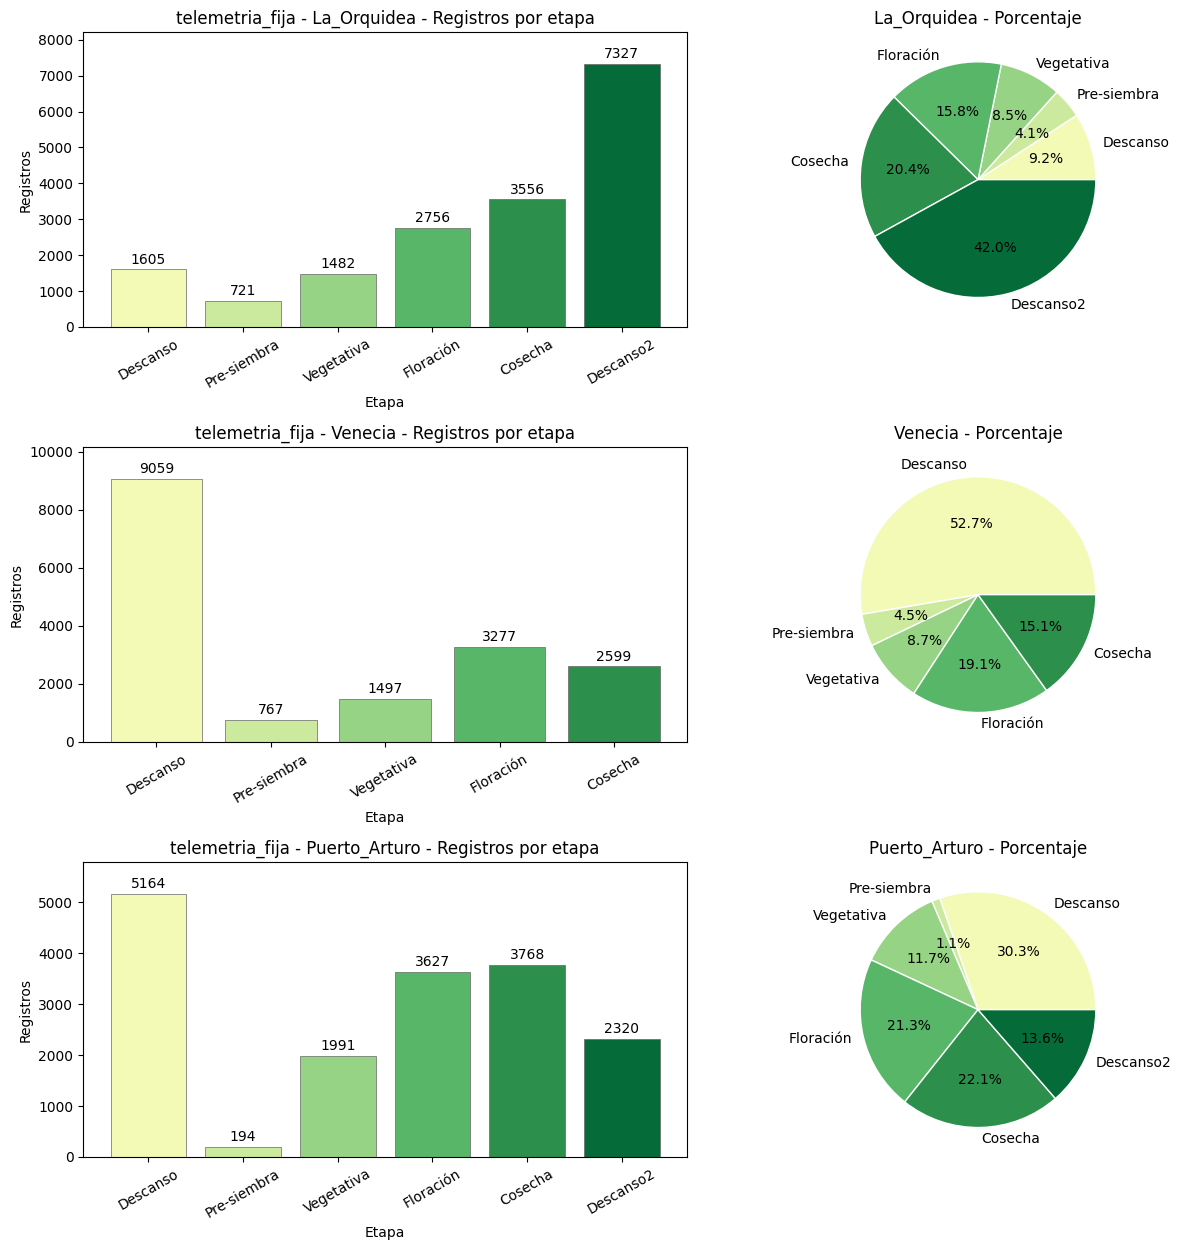

### Duración de las etapas - telemetria_fija

,Descanso,Pre-siembra,Vegetativa,Floración,Cosecha,Descanso2
La_Orquidea,4 semanas y 6 días (34 días),2 semanas y 1 día (15 días),4 semanas y 6 días (34 días),8 semanas y 1 día (57 días),10 semanas y 3 días (73 días),21 semanas y 4 días (151 días)
Venecia,28 semanas (196 días),2 semanas y 2 días (16 días),4 semanas y 3 días (31 días),9 semanas y 4 días (67 días),7 semanas y 5 días (54 días),-
Puerto_Arturo,15 semanas y 3 días (108 días),4 días,5 semanas y 5 días (40 días),12 semanas y 1 día (85 días),11 semanas y 2 días (79 días),6 semanas y 6 días (48 días)


In [23]:
conteos_etapas_fija = graficar_registros_por_etapa(BD_FIJA_FILTERED, NOMBRE_BD_FIJA)
conteos_etapas_fija

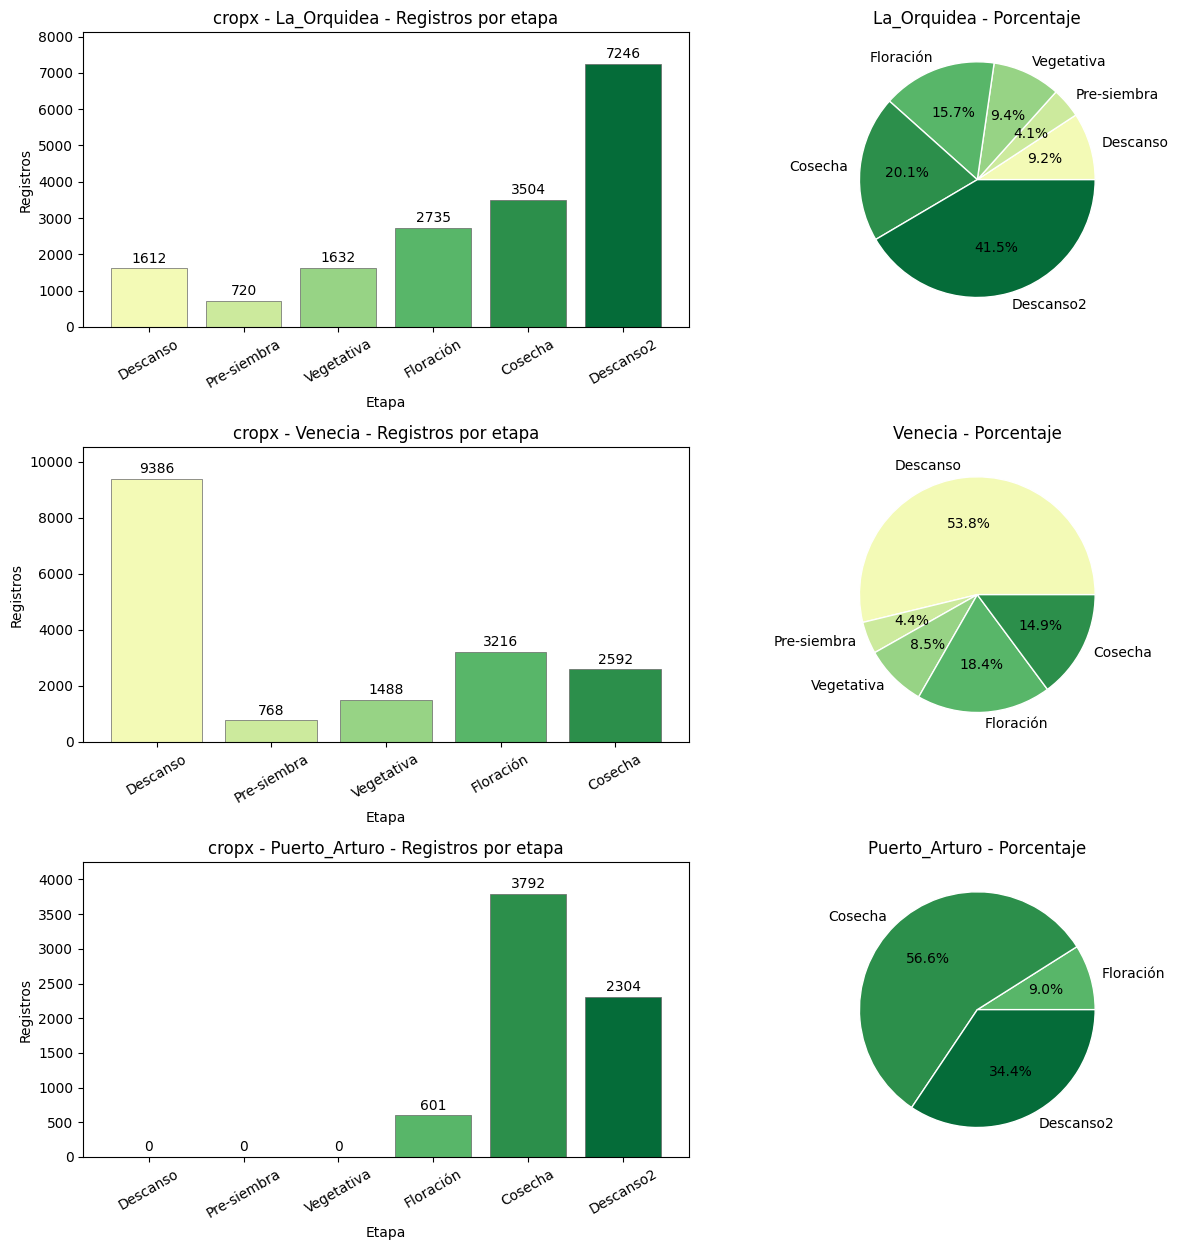

### Duración de las etapas - cropx

,Descanso,Pre-siembra,Vegetativa,Floración,Cosecha,Descanso2
La_Orquidea,4 semanas y 6 días (34 días),2 semanas y 1 día (15 días),4 semanas y 6 días (34 días),8 semanas y 1 día (57 días),10 semanas y 3 días (73 días),21 semanas y 4 días (151 días)
Venecia,28 semanas (196 días),2 semanas y 2 días (16 días),4 semanas y 3 días (31 días),9 semanas y 4 días (67 días),7 semanas y 5 días (54 días),-
Puerto_Arturo,15 semanas y 3 días (108 días),4 días,5 semanas y 5 días (40 días),12 semanas y 1 día (85 días),11 semanas y 2 días (79 días),6 semanas y 6 días (48 días)


In [24]:
conteos_etapas_cropx = graficar_registros_por_etapa(BD_CROPX, NOMBRE_BD_CROPX)
conteos_etapas_cropx

# Cobertura por etapa
Registros de cada etapa (y su porcentaje sobre el total de la finca), variables que no tienen ningún dato en la etapa y cuáles son.

In [19]:
# =============================================================================
# 2. COBERTURA POR ETAPA: registros incompletos según las variables que les faltan
# =============================================================================
def variables_base(df: pd.DataFrame) -> list[str]:
    """Variables numéricas de la base (sin lat/lon), aunque estén vacías.

    Args:
        df (pd.DataFrame): Datos de una finca.

    Returns:
        list[str]: Nombres de las variables.
    """
    return df.select_dtypes(include=np.number).drop(columns=["lat", "lon"], errors="ignore").columns.tolist()


def tabla_cobertura_etapas(bd: dict[str, pd.DataFrame], max_combinaciones: int = 10) -> pd.DataFrame:
    """Por finca y etapa: cuántos registros están incompletos y qué variables les faltan.

    Cada fila es una combinación de variables faltantes; p. ej. "50 registros sin datos de 8 variables"
    y "20 registros sin datos de 3 variables" son dos filas de la misma etapa.

    Args:
        bd (dict[str, pd.DataFrame]): {finca: datos con índice temporal} (BD_FIJA_FILTERED o BD_CROPX).
        max_combinaciones (int): Combinaciones mostradas por etapa; el resto se suma en "Otras combinaciones".

    Returns:
        pd.DataFrame: Columnas Finca, Etapa, #Registros (Porcentaje), #Variables sin Datos, Variables.
            El porcentaje es sobre el total de registros de la etapa.
    """
    filas = []
    for finca, df in bd.items():
        variables = list(columnas_analisis(df))           # variables con algún dato en la finca
        for etapa in obtener_rangos(FINCAS_POR_NOMBRE[finca]):
            datos = filtrar_etapa(df, finca, etapa)[variables]
            total = len(datos)
            fila = {"Finca": finca, "Etapa": etapa}

            if total == 0:
                filas.append({**fila, "#Registros (Porcentaje)": "0 (etapa sin registros)",
                              "#Variables sin Datos": np.nan, "Variables": "-"})
                continue

            faltantes = datos.isna()
            incompletos = faltantes[faltantes.any(axis=1)]
            if incompletos.empty:
                filas.append({**fila, "#Registros (Porcentaje)": f"0 (0.0 % de {total})",
                              "#Variables sin Datos": 0, "Variables": "Todos los registros completos"})
                continue

            # Cuántos registros tienen cada combinación de variables faltantes
            combinaciones = [([v for v, falta in zip(variables, clave) if falta], n)
                             for clave, n in incompletos.value_counts().items()]
            combinaciones.sort(key=lambda c: (-len(c[0]), -c[1]))   # más variables faltantes primero

            for nombres, n in combinaciones[:max_combinaciones]:
                texto = f"Todas ({len(variables)})" if len(nombres) == len(variables) else ", ".join(nombres)
                filas.append({**fila, "#Registros (Porcentaje)": f"{n} ({100 * n / total:.1f} %)",
                              "#Variables sin Datos": len(nombres), "Variables": texto})

            resto = combinaciones[max_combinaciones:]
            if resto:
                n = sum(c[1] for c in resto)
                filas.append({**fila, "#Registros (Porcentaje)": f"{n} ({100 * n / total:.1f} %)",
                              "#Variables sin Datos": np.nan,
                              "Variables": f"Otras combinaciones ({len(resto)})"})
    return pd.DataFrame(filas, columns=["Finca", "Etapa", "#Registros (Porcentaje)",
                                        "#Variables sin Datos", "Variables"])


def mostrar_tabla_cobertura(bd: dict[str, pd.DataFrame], nombre_bd: str,
                            max_combinaciones: int = 10) -> pd.DataFrame:
    """Muestra los registros incompletos por etapa (rojo = más variables sin datos).

    Args:
        bd (dict[str, pd.DataFrame]): {finca: datos con índice temporal}.
        nombre_bd (str): Nombre de la base para el título.
        max_combinaciones (int): Combinaciones mostradas por etapa.

    Returns:
        pd.DataFrame: La tabla mostrada.
    """
    display(Markdown(f"### Registros incompletos por etapa - {nombre_bd}"))
    if not bd:
        display(Markdown("_No hay fincas cargadas en esta base._"))
        return pd.DataFrame()

    for finca, df in bd.items():                          # variables nunca medidas: no se cuentan
        nunca = [v for v in variables_base(df) if v not in columnas_analisis(df)]
        if nunca:
            display(Markdown(f"_{finca}: sin ningún dato en todo el periodo (no se cuentan): {', '.join(nunca)}_"))

    tabla = tabla_cobertura_etapas(bd, max_combinaciones)
    display(tabla.style.hide(axis="index")
            .background_gradient(subset=["#Variables sin Datos"], cmap="Reds", vmin=0)
            .format({"#Variables sin Datos": "{:.0f}"}, na_rep="-")
            .set_properties(subset=["Variables"], **{"text-align": "left", "white-space": "normal"}))
    return tabla

In [20]:
cobertura_fija = mostrar_tabla_cobertura(BD_FIJA_FILTERED, NOMBRE_BD_FIJA)

### Registros incompletos por etapa - telemetria_fija

Finca,Etapa,#Registros (Porcentaje),#Variables sin Datos,Variables
La_Orquidea,Descanso,844 (52.6 %),13,"medium_moisture41_pred, medium_ecpw41_pred, top_moisture20_pred, top_ecpw20_pred, conductivity_est_extratrees_20cm, conductivity_est_extratrees_40cm, conductivity_est_extratrees_60cm, conductivity_est_randomforest_20cm, conductivity_est_randomforest_40cm, conductivity_est_randomforest_60cm, conductivity_est_lightgbm_20cm, conductivity_est_lightgbm_40cm, conductivity_est_lightgbm_60cm"
La_Orquidea,Descanso,761 (47.4 %),9,"conductivity_est_extratrees_20cm, conductivity_est_extratrees_40cm, conductivity_est_extratrees_60cm, conductivity_est_randomforest_20cm, conductivity_est_randomforest_40cm, conductivity_est_randomforest_60cm, conductivity_est_lightgbm_20cm, conductivity_est_lightgbm_40cm, conductivity_est_lightgbm_60cm"
La_Orquidea,Pre-siembra,721 (100.0 %),13,"medium_moisture41_pred, medium_ecpw41_pred, top_moisture20_pred, top_ecpw20_pred, conductivity_est_extratrees_20cm, conductivity_est_extratrees_40cm, conductivity_est_extratrees_60cm, conductivity_est_randomforest_20cm, conductivity_est_randomforest_40cm, conductivity_est_randomforest_60cm, conductivity_est_lightgbm_20cm, conductivity_est_lightgbm_40cm, conductivity_est_lightgbm_60cm"
La_Orquidea,Vegetativa,1482 (100.0 %),13,"medium_moisture41_pred, medium_ecpw41_pred, top_moisture20_pred, top_ecpw20_pred, conductivity_est_extratrees_20cm, conductivity_est_extratrees_40cm, conductivity_est_extratrees_60cm, conductivity_est_randomforest_20cm, conductivity_est_randomforest_40cm, conductivity_est_randomforest_60cm, conductivity_est_lightgbm_20cm, conductivity_est_lightgbm_40cm, conductivity_est_lightgbm_60cm"
La_Orquidea,Floración,2756 (100.0 %),13,"medium_moisture41_pred, medium_ecpw41_pred, top_moisture20_pred, top_ecpw20_pred, conductivity_est_extratrees_20cm, conductivity_est_extratrees_40cm, conductivity_est_extratrees_60cm, conductivity_est_randomforest_20cm, conductivity_est_randomforest_40cm, conductivity_est_randomforest_60cm, conductivity_est_lightgbm_20cm, conductivity_est_lightgbm_40cm, conductivity_est_lightgbm_60cm"
La_Orquidea,Cosecha,3556 (100.0 %),13,"medium_moisture41_pred, medium_ecpw41_pred, top_moisture20_pred, top_ecpw20_pred, conductivity_est_extratrees_20cm, conductivity_est_extratrees_40cm, conductivity_est_extratrees_60cm, conductivity_est_randomforest_20cm, conductivity_est_randomforest_40cm, conductivity_est_randomforest_60cm, conductivity_est_lightgbm_20cm, conductivity_est_lightgbm_40cm, conductivity_est_lightgbm_60cm"
La_Orquidea,Descanso2,657 (9.0 %),36,"bottom_nitrogen_60cm, bottom_phosphorus_60cm, bottom_potassium_60cm, bottom_ph_60cm, bottom_moisture_60cm, bottom_temperature_60cm, bottom_conductivity_60cm, medium_nitrogen_40cm, medium_phosphorus_40cm, medium_potassium_40cm, medium_ph_40cm, medium_moisture_40cm, medium_temperature_40cm, medium_conductivity_40cm, medium_moisture41_pred, medium_ecpw41_pred, top_nitrogen_20cm, top_phosphorus_20cm, top_potassium_20cm, top_ph_20cm, top_moisture_20cm, top_temperature_20cm, top_conductivity_20cm, top_moisture20_pred, top_ecpw20_pred, conductivity_est_extratrees_20cm, conductivity_est_extratrees_40cm, conductivity_est_extratrees_60cm, conductivity_est_randomforest_20cm, conductivity_est_randomforest_40cm, conductivity_est_randomforest_60cm, conductivity_est_lightgbm_20cm, conductivity_est_lightgbm_40cm, conductivity_est_lightgbm_60cm, air_temperature, air_humidity"
La_Orquidea,Descanso2,763 (10.4 %),13,"medium_moisture41_pred, medium_ecpw41_pred, top_moisture20_pred, top_ecpw20_pred, conductivity_est_extratrees_20cm, conductivity_est_extratrees_40cm, conductivity_est_extratrees_60cm, conductivity_est_randomforest_20cm, conductivity_est_randomforest_40cm, conductivity_est_randomforest_60cm, conductivity_est_lightgbm_20cm, conductivity_est_lightgbm_40cm, conductivity_est_lightgbm_60cm"
La_Orquidea,Descanso2,3079 (42.0 %),10,"medium_moisture41_pred, medium_ecpw41_pred, top_moisture20_pred, top_ec

In [21]:
cobertura_cropx = mostrar_tabla_cobertura(BD_CROPX, NOMBRE_BD_CROPX)

### Registros incompletos por etapa - cropx

Finca,Etapa,#Registros (Porcentaje),#Variables sin Datos,Variables
La_Orquidea,Descanso,1 (0.1 %),1,ECpw 41
La_Orquidea,Pre-siembra,0 (0.0 % de 720),0,Todos los registros completos
La_Orquidea,Vegetativa,0 (0.0 % de 1632),0,Todos los registros completos
La_Orquidea,Floración,1 (0.0 %),1,ECpw 66
La_Orquidea,Cosecha,0 (0.0 % de 3504),0,Todos los registros completos
La_Orquidea,Descanso2,1 (0.0 %),1,ECpw 66
Venecia,Descanso,0 (0.0 % de 9386),0,Todos los registros completos
Venecia,Pre-siembra,0 (0.0 % de 768),0,Todos los registros completos
Venecia,Vegetativa,0 (0.0 % de 1488),0,Todos los registros completos
Venecia,Floración,0 (0.0 % de 3216),0,Todos los registros completos


# Periodos sin datos
Huecos de información en cada etapa, buscados por hora o por día (`FRECUENCIA_HUECOS` en `config.py`).
Un periodo cuenta como "sin datos" si no llegó ningún registro con al menos una variable medida.

In [13]:
# =============================================================================
# 3. PERIODOS SIN DATOS POR ETAPA
# =============================================================================
def formato_duracion(duracion: pd.Timedelta) -> str:
    """Texto corto de una duración, p. ej. "3 d 7 h" o "5 h".

    Args:
        duracion (pd.Timedelta): Duración.

    Returns:
        str: Duración en días y horas (o minutos si es menor a una hora).
    """
    dias, horas = duracion.days, duracion.seconds // 3600
    if dias:
        return f"{dias} d {horas} h" if horas else f"{dias} d"
    return f"{horas} h" if horas else f"{duracion.seconds // 60} min"


def huecos_en_rango(df: pd.DataFrame, t_ini: pd.Timestamp, t_fin: pd.Timestamp,
                    frecuencia: str = "1h") -> list[tuple[pd.Timestamp, pd.Timestamp]]:
    """Intervalos (hora o día) del rango en los que no hay ningún registro con datos.

    Args:
        df (pd.DataFrame): Datos de la finca ya recortados al rango.
        t_ini (pd.Timestamp): Inicio del rango.
        t_fin (pd.Timestamp): Fin del rango (exclusivo).
        frecuencia (str): Resolución de la búsqueda ("1h" por hora, "1D" por día).

    Returns:
        list[tuple[pd.Timestamp, pd.Timestamp]]: (inicio, fin) de cada periodo seguido sin datos.
    """
    rejilla = pd.date_range(t_ini.floor(frecuencia), t_fin, freq=frecuencia, inclusive="left")
    if rejilla.empty:
        return []
    con_datos = df.index[df.notna().any(axis=1)].floor(frecuencia)
    vacio = pd.Series(~rejilla.isin(con_datos), index=rejilla)

    bloques = (vacio != vacio.shift()).cumsum()            # numera cada racha de vacío / con datos
    paso = pd.tseries.frequencies.to_offset(frecuencia)
    huecos = []
    for _, racha in vacio[vacio].groupby(bloques[vacio]):
        huecos.append((max(racha.index[0], t_ini), min(racha.index[-1] + paso, t_fin)))
    return huecos


def tabla_periodos_sin_datos(bd: dict[str, pd.DataFrame], frecuencia: str = "1h",
                             duracion_minima: str | None = None) -> pd.DataFrame:
    """Por finca y etapa: cada periodo seguido sin datos. Las etapas sin huecos aparecen como "Ninguno".

    Args:
        bd (dict[str, pd.DataFrame]): {finca: datos con índice temporal} (BD_FIJA_FILTERED o BD_CROPX).
        frecuencia (str): Resolución de la búsqueda ("1h" por hora, "1D" por día).
        duracion_minima (str | None): Solo reportar huecos de al menos esta duración (p. ej. "6h"); None = todos.

    Returns:
        pd.DataFrame: Columnas Finca, Etapa, Periodo sin Datos, Duración, Horas sin datos.
    """
    minimo = pd.Timedelta(duracion_minima) if duracion_minima else pd.Timedelta(0)
    filas = []
    for finca, df in bd.items():
        variables = variables_base(df)
        for etapa, (inicio, fin) in obtener_rangos(FINCAS_POR_NOMBRE[finca]).items():
            t_ini, t_fin = _limites_rango(inicio, fin)
            datos = filtrar_etapa(df, finca, etapa)[variables]
            huecos = [h for h in huecos_en_rango(datos, t_ini, t_fin, frecuencia) if h[1] - h[0] >= minimo]
            for h_ini, h_fin in huecos:
                filas.append({"Finca": finca, "Etapa": etapa,
                              "Periodo sin Datos": f"{h_ini:%d/%m/%Y %H:%M} a {h_fin:%d/%m/%Y %H:%M}",
                              "Duración": formato_duracion(h_fin - h_ini),
                              "Horas sin datos": (h_fin - h_ini) / pd.Timedelta("1h")})
            if not huecos:
                filas.append({"Finca": finca, "Etapa": etapa, "Periodo sin Datos": "Ninguno",
                              "Duración": "-", "Horas sin datos": 0.0})
    return pd.DataFrame(filas, columns=["Finca", "Etapa", "Periodo sin Datos", "Duración", "Horas sin datos"])


def resumen_periodos_sin_datos(tabla: pd.DataFrame) -> pd.DataFrame:
    """Cantidad de periodos sin datos y horas totales sin datos por finca y etapa.

    Args:
        tabla (pd.DataFrame): Salida de `tabla_periodos_sin_datos`.

    Returns:
        pd.DataFrame: Periodos sin datos y horas sin datos por finca y etapa.
    """
    con_hueco = tabla["Periodo sin Datos"] != "Ninguno"
    return (tabla.assign(Periodos=con_hueco.astype(int))
            .groupby(["Finca", "Etapa"], sort=False)
            .agg(**{"Periodos sin datos": ("Periodos", "sum"), "Horas sin datos": ("Horas sin datos", "sum")}))


def reportar_periodos_sin_datos(bd: dict[str, pd.DataFrame], nombre_bd: str, frecuencia: str = FRECUENCIA_HUECOS,
                                duracion_minima: str | None = None, guardar: bool = True) -> pd.DataFrame:
    """Muestra el resumen y el detalle de periodos sin datos y, si se pide, lo guarda en Excel.

    Args:
        bd (dict[str, pd.DataFrame]): {finca: datos con índice temporal}.
        nombre_bd (str): Nombre de la base (títulos y nombre del archivo).
        frecuencia (str): Resolución de la búsqueda ("1h" o "1D").
        duracion_minima (str | None): Solo reportar huecos de al menos esta duración; None = todos.
        guardar (bool): True para guardar DIR_SALIDA/periodos_sin_datos_{nombre_bd}.xlsx.

    Returns:
        pd.DataFrame: Tabla detallada.
    """
    tabla = tabla_periodos_sin_datos(bd, frecuencia, duracion_minima)
    display(Markdown(f"### Periodos sin datos - {nombre_bd} (búsqueda por {frecuencia})"))
    if tabla.empty:
        display(Markdown("_No hay fincas cargadas en esta base._"))
        return tabla
    resumen = resumen_periodos_sin_datos(tabla)
    display(resumen.style.background_gradient(subset=["Horas sin datos"], cmap="Reds").format(
        {"Horas sin datos": "{:.0f}"}))
    display(tabla.drop(columns="Horas sin datos").style.hide(axis="index"))
    if guardar:
        DIR_SALIDA.mkdir(parents=True, exist_ok=True)
        ruta = DIR_SALIDA / f"periodos_sin_datos_{nombre_bd}.xlsx"
        with pd.ExcelWriter(ruta) as excel:
            resumen.reset_index().to_excel(excel, sheet_name="Resumen", index=False)
            tabla.to_excel(excel, sheet_name="Detalle", index=False)
        print(f"Guardado: {ruta}")
    return tabla

In [14]:
periodos_sin_datos_fija = reportar_periodos_sin_datos(BD_FIJA_FILTERED, NOMBRE_BD_FIJA)

### Periodos sin datos - telemetria_fija (búsqueda por 1h)

Finca,Etapa,Periodo sin Datos,Duración
La_Orquidea,Descanso,21/10/2025 00:00 a 21/10/2025 09:00,9 h
La_Orquidea,Descanso,21/10/2025 11:00 a 21/10/2025 14:00,3 h
La_Orquidea,Descanso,03/11/2025 08:00 a 03/11/2025 10:00,2 h
La_Orquidea,Pre-siembra,27/11/2025 09:00 a 27/11/2025 14:00,5 h
La_Orquidea,Vegetativa,30/12/2025 00:00 a 02/01/2026 07:00,3 d 7 h
La_Orquidea,Floración,17/01/2026 11:00 a 17/01/2026 12:00,1 h
La_Orquidea,Floración,26/01/2026 16:00 a 27/01/2026 06:00,14 h
La_Orquidea,Floración,26/02/2026 09:00 a 27/02/2026 09:00,1 d
La_Orquidea,Cosecha,28/04/2026 15:00 a 28/04/2026 22:00,7 h
La_Orquidea,Cosecha,29/04/2026 10:00 a 29/04/2026 11:00,1 h


Guardado: D:\Estudio\OneDrive - Universidad de Antioquia\Estudio\PAI\Nuevos-Modelos-Paulina\Code\Data_Exploration\EDA_telemetria_v2\outputs\EDA_telemetria_fija\periodos_sin_datos_telemetria_fija.xlsx


In [15]:
periodos_sin_datos_cropx = reportar_periodos_sin_datos(BD_CROPX, NOMBRE_BD_CROPX)

### Periodos sin datos - cropx (búsqueda por 1h)

Finca,Etapa,Periodo sin Datos,Duración
La_Orquidea,Descanso,21/10/2025 00:00 a 21/10/2025 10:00,10 h
La_Orquidea,Pre-siembra,Ninguno,-
La_Orquidea,Vegetativa,Ninguno,-
La_Orquidea,Floración,Ninguno,-
La_Orquidea,Cosecha,Ninguno,-
La_Orquidea,Descanso2,19/10/2026 23:00 a 20/10/2026 00:00,1 h
Venecia,Descanso,21/10/2025 00:00 a 21/10/2025 11:00,11 h
Venecia,Pre-siembra,Ninguno,-
Venecia,Vegetativa,Ninguno,-
Venecia,Floración,Ninguno,-


Guardado: D:\Estudio\OneDrive - Universidad de Antioquia\Estudio\PAI\Nuevos-Modelos-Paulina\Code\Data_Exploration\EDA_telemetria_v2\outputs\EDA_telemetria_fija\periodos_sin_datos_cropx.xlsx


# Missings

In [16]:
# =========================================================
# 8. VALORES FALTANTES POR ETAPA
# =========================================================

def graficar_faltantes_por_etapa(bd: dict[str, pd.DataFrame], nombre_bd: str) -> None:
    """Barras: cuántos registros tienen 1, 2, 3, ... variables sin dato, por finca (filas) y etapa (columnas).

    Args:
        bd (dict[str, pd.DataFrame]): {finca: datos con índice temporal} (BD_FIJA_FILTERED o BD_CROPX).
        nombre_bd (str): Nombre de la base para el título.

    Returns:
        None: Muestra la figura.
    """
    fincas = list(bd)
    if not fincas:
        mostrar_sin_datos(f"Faltantes por etapa - {nombre_bd}", "No hay fincas cargadas en esta base")
        return
    etapas = list(dict.fromkeys(e for f in fincas for e in obtener_rangos(FINCAS_POR_NOMBRE[f])))

    fig, axes = plt.subplots(len(fincas), len(etapas), figsize=(4 * len(etapas), 3 * len(fincas)),
                             sharex=True, squeeze=False)

    for i, finca in enumerate(fincas):
        columnas = columnas_analisis(bd[finca])
        for j, etapa in enumerate(etapas):
            ax = axes[i, j]
            if etapa not in obtener_rangos(FINCAS_POR_NOMBRE[finca]):
                ax.set_visible(False)
                continue

            datos = filtrar_etapa(bd[finca], finca, etapa)[columnas]
            n_faltantes = datos.isna().sum(axis=1)               # variables sin dato en cada registro
            conteo = n_faltantes[n_faltantes > 0].value_counts().sort_index()

            ax.bar(conteo.index, conteo.values, color="steelblue")
            ax.set_xlim(0.5, len(columnas) + 0.5)
            ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
            if conteo.empty:
                aviso = "Sin datos en esta etapa" if datos.empty else "Sin faltantes"
                ax.text(0.5, 0.5, aviso, transform=ax.transAxes, ha="center")
                ax.set_yticks([])
            ax.set_title(f"{finca} - {etapa}\n{len(datos)} registros, "
                         f"{(n_faltantes == 0).sum()} completos", fontsize=10)
            if j == 0:
                ax.set_ylabel("Registros")
            if i == len(fincas) - 1:
                ax.set_xlabel(f"Variables sin dato (de {len(columnas)})")

    fig.suptitle(f"Valores faltantes por etapa - {nombre_bd}", y=1.0)
    plt.tight_layout()
    plt.show()

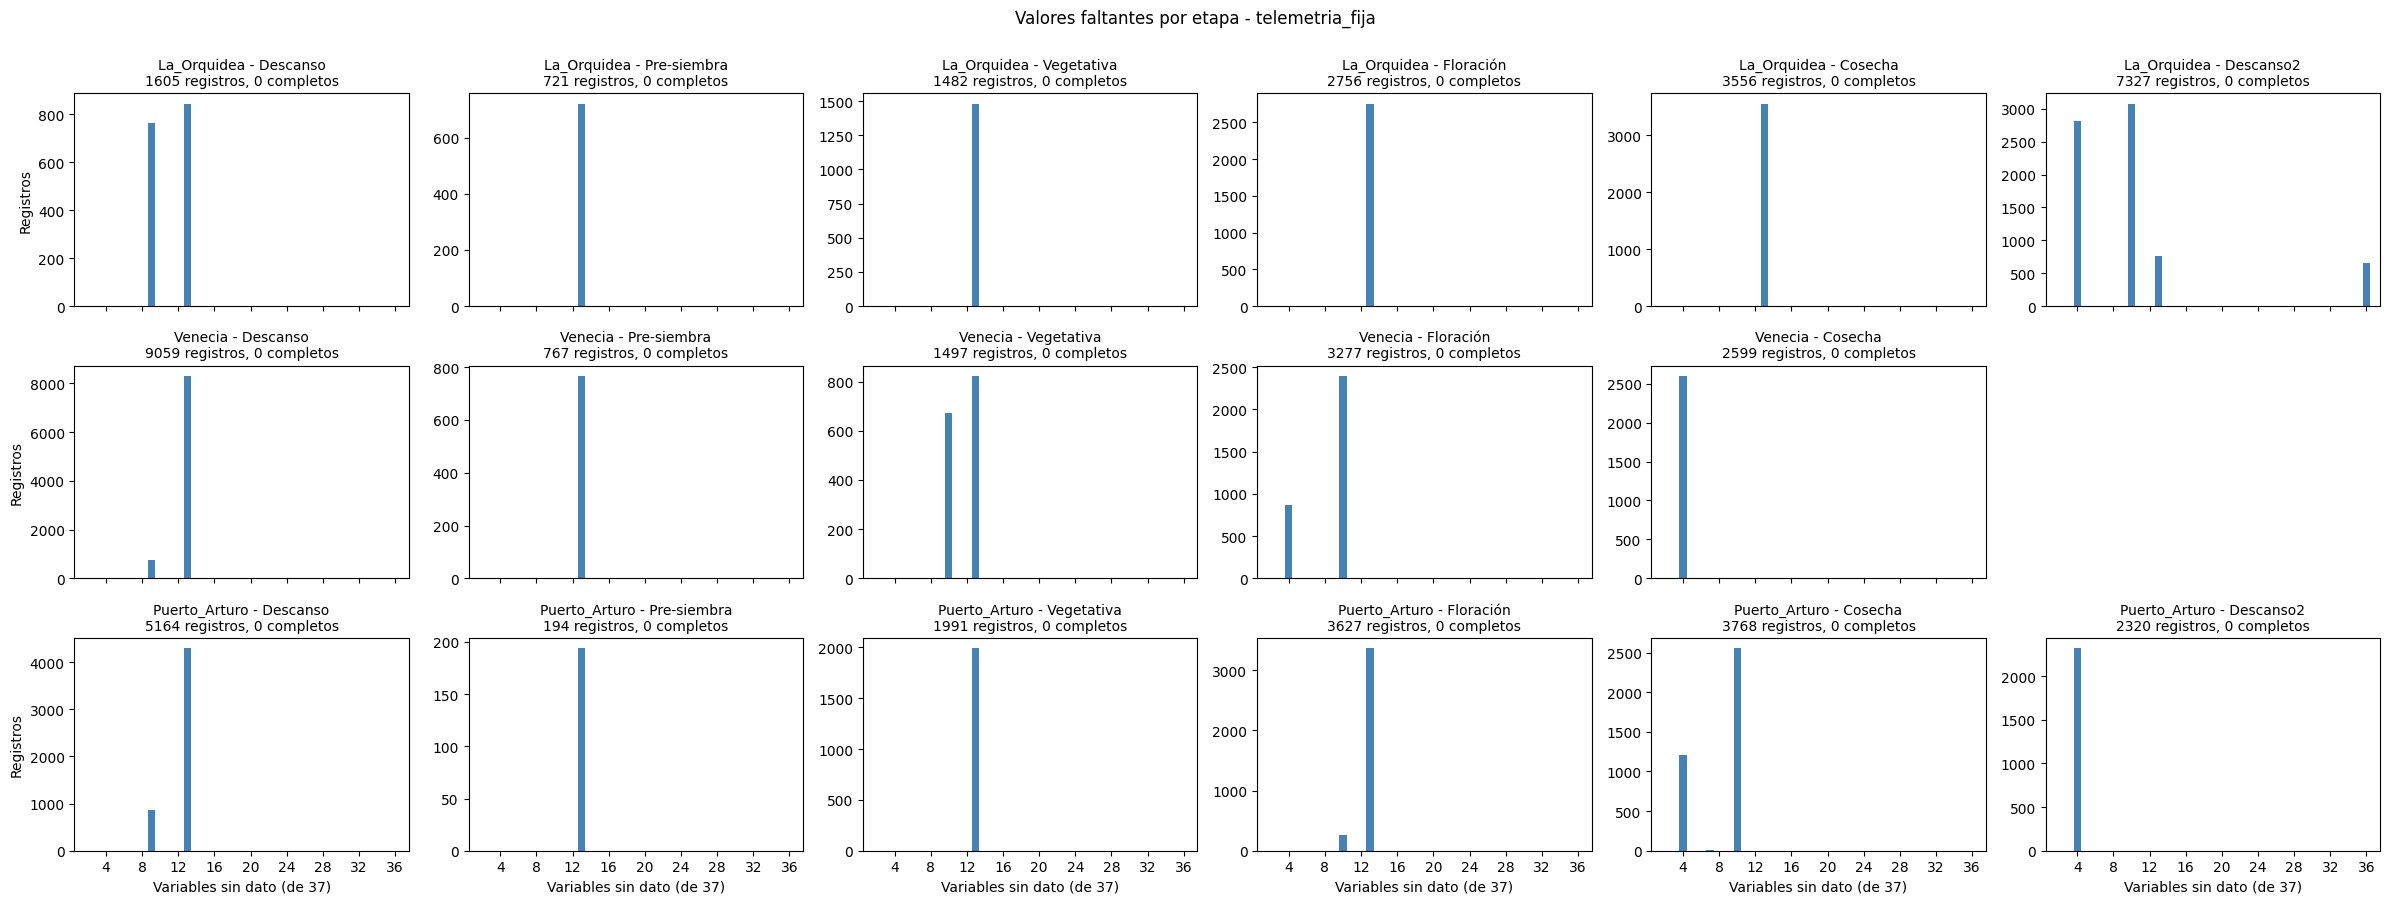

In [17]:
graficar_faltantes_por_etapa(BD_FIJA_FILTERED, NOMBRE_BD_FIJA)

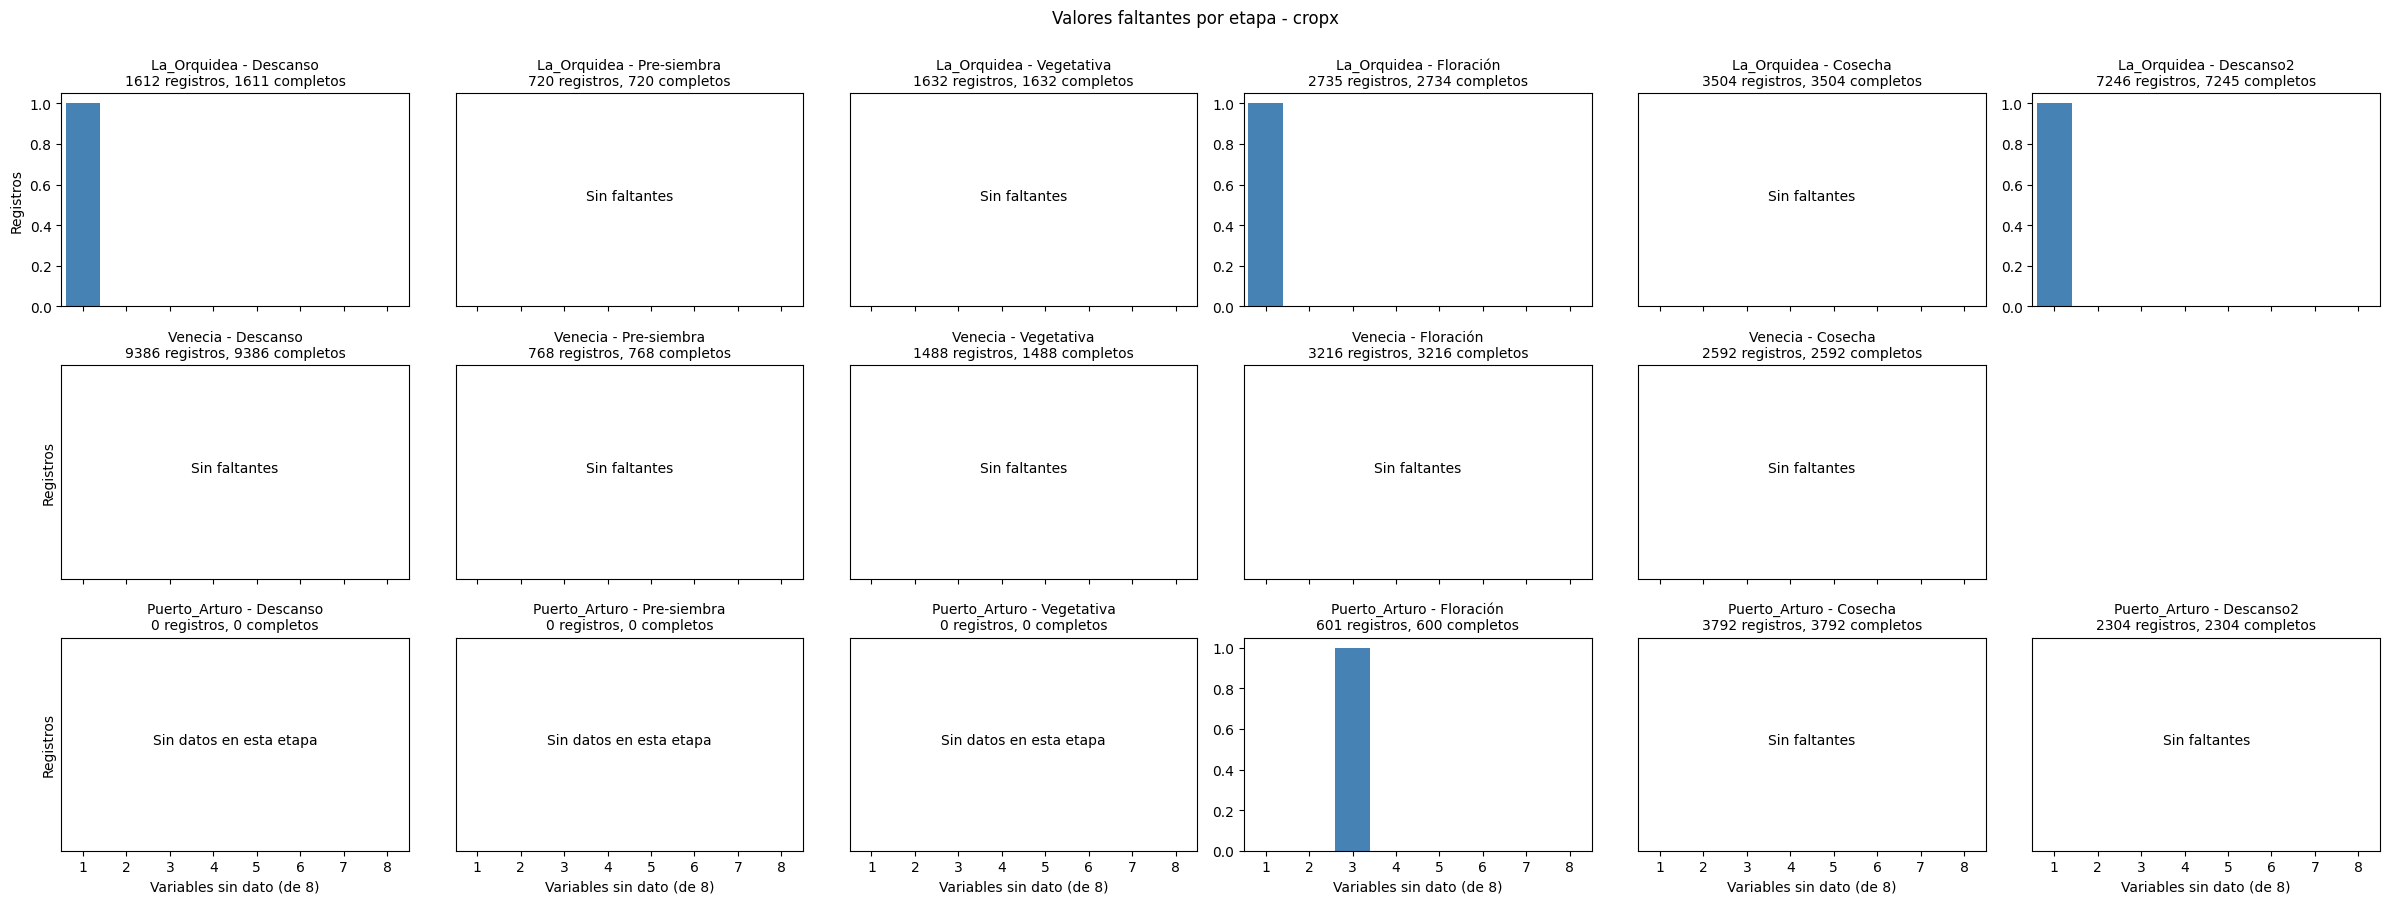

In [18]:
graficar_faltantes_por_etapa(BD_CROPX, NOMBRE_BD_CROPX)